In [1]:
import sys
sys.path.append("..")

from sklearn.metrics import confusion_matrix

from src.data_prep import load_data, split_data
from src.models import get_models

df = load_data()
X_train, X_test, y_train, y_test = split_data(df)

models = get_models()
for name, model in models.items():
    model.fit(X_train, y_train)

y_pred = models["Logistic Regression"].predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[926 109]
 [165 209]]


In [2]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.806,0.657,0.559,0.604,0.842
Decision Tree,0.721,0.475,0.487,0.481,0.646
Random Forest,0.786,0.624,0.484,0.545,0.817
XGBoost,0.776,0.590,0.519,0.552,0.820


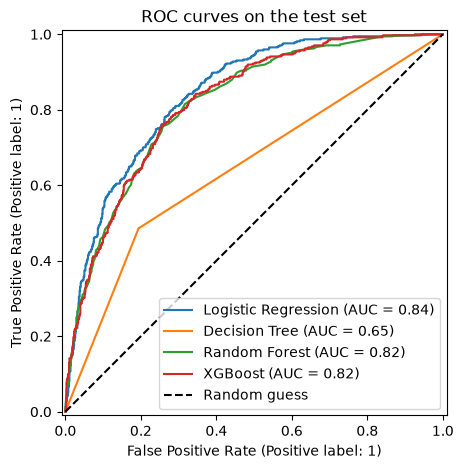

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))

for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.legend()
ax.set_title("ROC curves on the test set")
plt.show()